# 04 - Modelado

## Objetivo de este cuaderno

Entrenamos una regresión lineal como línea base para predecir price y medimos su error en euros.

- **Lee:** X_train_esc.csv, X_test_esc.csv, y_train.csv e y_test.csv de data/processed
- **Guarda:** el modelo en models/regresion_lineal.joblib, la figura 11 en outputs/figures y las métricas en outputs/metricas_lineal.csv

### Importar librerías

Cargamos pandas, numpy y matplotlib. Las herramientas de sklearn se importan en la celda donde se usan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Cargar los datos

La regresión lineal usa los datos escalados. y está guardada como una tabla con una columna, price, que contiene el logaritmo del precio; nos quedamos con esa columna.

In [2]:
X_train_esc = pd.read_csv('../data/processed/X_train_esc.csv')
X_test_esc = pd.read_csv('../data/processed/X_test_esc.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')['price']
y_test = pd.read_csv('../data/processed/y_test.csv')['price']
print(X_train_esc.shape, X_test_esc.shape, y_train.shape, y_test.shape)

(32491, 26) (8123, 26) (32491,) (8123,)


# Regresión lineal

### Entrenar el modelo

La regresión lineal busca un peso (coeficiente) para cada variable, de forma que la suma ponderada se parezca lo más posible al logaritmo del precio.

In [3]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train_esc, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](26,)","[ 0.2 ,-0.17, 0.25,...,-0.02,-0.01, 0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](26,)","['model','kms','power',...,'make_RENAULT','make_SEAT','make_VOLKSWAGEN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.489
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,26
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(24)


### Predecir

El modelo predice el logaritmo del precio. Para medir el error en euros, deshacemos el logaritmo con np.exp, tanto en las predicciones como en los precios reales.

In [4]:
pred_train_log = reg.predict(X_train_esc)
pred_test_log = reg.predict(X_test_esc)
pred_train = np.exp(pred_train_log)
pred_test = np.exp(pred_test_log)
real_train = np.exp(y_train)
real_test = np.exp(y_test)

# Métricas

- **MAE:** cuántos euros nos equivocamos de media en cada coche.
- **MAPE:** cuánto nos equivocamos de media en porcentaje del precio; un error de 1.000 € pesa más en un coche de 5.000 € que en uno de 50.000 €.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **R2:** qué parte de la variación del logaritmo del precio explica el modelo (1 sería perfecto).

Las calculamos en train y en test. Si en train salieran mucho mejor que en test, el modelo estaría memorizando (sobreajuste).

In [5]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

In [7]:
mae_train = mean_absolute_error(real_train, pred_train)
mape_train = mean_absolute_percentage_error(real_train, pred_train) * 100
rmse_train = np.sqrt(mean_squared_error(real_train, pred_train))
r2_train = r2_score(y_train, pred_train_log)

In [8]:
mae_test = mean_absolute_error(real_test, pred_test)
mape_test = mean_absolute_percentage_error(real_test, pred_test) * 100
rmse_test = np.sqrt(mean_squared_error(real_test, pred_test))
r2_test = r2_score(y_test, pred_test_log)

Juntamos las métricas en una tabla.

In [9]:
metricas = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [mae_train, mae_test],
    'MAPE (%)': [mape_train, mape_test],
    'RMSE (€)': [rmse_train, rmse_test],
    'R2 (log)': [r2_train, r2_test]
})
metricas.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,2619.699,16.791,5110.706,0.906
1,test,2664.474,16.803,5301.915,0.907


### Coches con un error menor del 15 %

El margen de la empresa ronda el 15 %. Miramos en qué porcentaje de coches de test el error de la tasación queda por debajo de ese margen.

In [10]:
error_relativo = np.abs(pred_test - real_test) / real_test
dentro_margen = (error_relativo < 0.15).mean() * 100
print(round(dentro_margen, 1))

58.7


### Coeficientes

En 03_preprocesado dejamos todas las categorías de combustible y de marca. Esas columnas son redundantes entre sí (en cada grupo siempre suman 1), así que miramos si algún coeficiente sale desproporcionado.

In [12]:
coef = pd.Series(reg.coef_, index=X_train_esc.columns)
coef.sort_values()

age                       -0.327527
kms                       -0.170274
fuel_Gasolina             -0.027468
make_OPEL                 -0.026786
doors                     -0.020673
isla                      -0.019747
make_CITROEN              -0.019629
make_FORD                 -0.016883
make_RENAULT              -0.016096
make_PEUGEOT              -0.015595
fuel_Híbrido enchufable   -0.012004
make_Other                -0.011196
make_SEAT                 -0.010783
fuel_Gas licuado (GLP)    -0.010108
fuel_Eléctrico            -0.008856
fuel_Híbrido              -0.004870
fuel_Gas natural (CNG)    -0.001946
make_BMW                   0.022295
make_MERCEDES-BENZ         0.027097
make_VOLKSWAGEN            0.028493
make_AUDI                  0.030696
is_professional            0.032000
fuel_Diésel                0.034191
shift                      0.049988
model                      0.196402
power                      0.248729
dtype: float64

In [13]:
reg.intercept_

np.float64(9.48869086576277)

### Real frente a predicho

Cada punto es un coche de test. Si la predicción fuera perfecta, todos los puntos estarían sobre la línea roja.

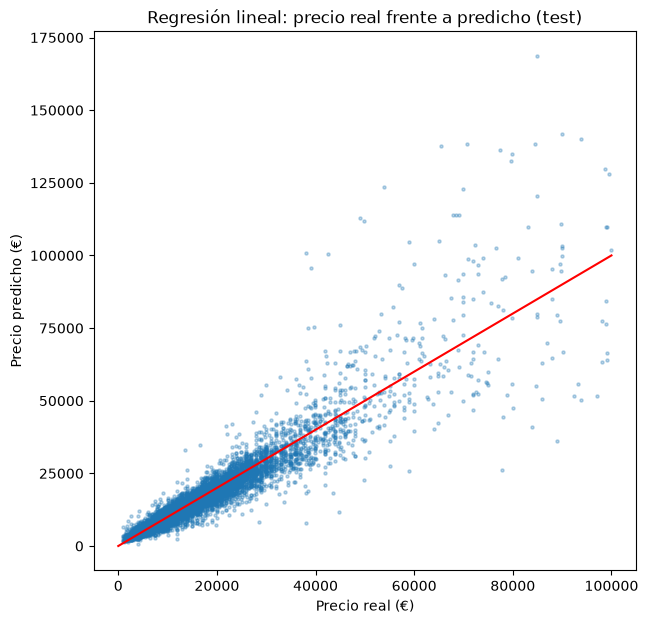

In [15]:
plt.figure(figsize=(7, 7))
plt.scatter(real_test, pred_test, s=5, alpha=0.3)
plt.plot([0, 100000], [0, 100000], color='red')
plt.xlabel('Precio real (€)')
plt.ylabel('Precio predicho (€)')
plt.title('Regresión lineal: precio real frente a predicho (test)')
plt.savefig('../outputs/figures/11_real_vs_predicho_lineal.png', bbox_inches='tight')
plt.show()

# Guardar el modelo y las métricas

Guardamos el modelo entrenado con joblib, que guarda el objeto de Python en un archivo para cargarlo después sin volver a entrenar.

In [16]:
import joblib
joblib.dump(reg, '../models/regresion_lineal.joblib')

['../models/regresion_lineal.joblib']

In [17]:
metricas.to_csv('../outputs/metricas_lineal.csv', index=False)

## Observaciones

- En test, la regresión lineal se equivoca de media 2.664 € por coche (MAE) y un 16,8 % del precio (MAPE). El RMSE es 5.302 €, bastante mayor que el MAE: hay algunos coches con errores grandes.
- El R2 en el logaritmo del precio es 0,907: el modelo explica la mayor parte de la variación.
- Train y test dan casi lo mismo (MAE 2.620 € frente a 2.664 €, R2 0,906 frente a 0,907), así que no hay sobreajuste.
- Solo el 58,7 % de los coches de test tiene un error menor del 15 %, que es el margen de la empresa, por lo que lo mejor es evaluar otros modelos.
- Los coeficientes no salen desproporcionados a pesar de las columnas redundantes: todos están entre -0,33 y 0,25. Las variables con más peso son age y kms (bajan el precio) y power y model (lo suben).
- Por esa redundancia, los coeficientes de combustible y de marca no se pueden leer uno a uno: solo tiene sentido compararlos entre sí dentro de cada grupo.